In [2]:
import numpy as np
from matplotlib import pyplot as plt

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

import dill

In [3]:
#device = "cuda" if torch.cuda.is_available() else "cpu"
device ="cpu"
print(f"Using {device} device")

Using cpu device


---

In [3]:
#def sigmoid(x):
#    x = torch.tensor(x)
#    return nn.functional.sigmoid(x).detach().numpy()

#def sigmoid(x):
#    return 1/(1+np.exp(-x))

# https://qiita.com/chersky/items/d74c9662a25c4e84565f
def sigmoid(x):
    return np.exp(np.minimum(x, 0)) / (1 + np.exp(- np.abs(x)))

In [4]:
f = lambda x: sigmoid((x+0.5)*10)

In [5]:
N = 100
#x = np.random.rand(N)*2-1

#y = f(x).reshape(N,1)

#outputを2つにする場合
#y = np.block( [sigmoid((x+0.5)*10).reshape(N,1),sigmoid((x-0.2)*10).reshape(N,1),] ) #np.expand_dims(x,1)でもいける

#plt.plot(x,y,'.')
#plt.show()

In [6]:
x,y = np.load("orig_data.npy")
N = x.size

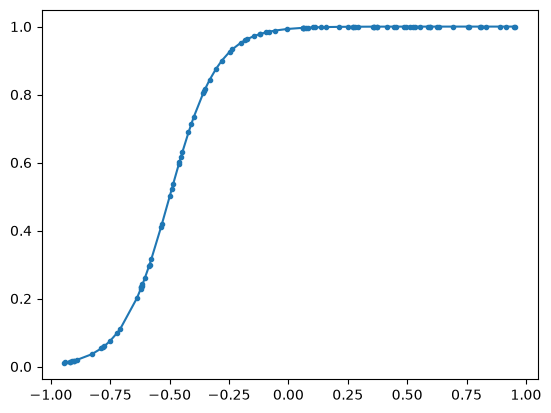

In [7]:
plt.plot( np.sort(np.array([x,y]))[0,:],np.sort(np.array([x,y]))[1,:] ,'.-') 

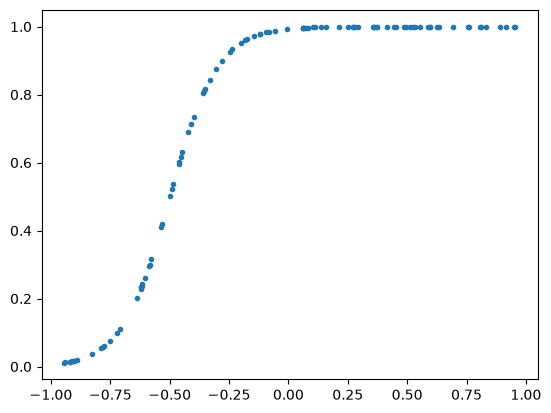

In [8]:
plt.plot(x,y,'.')
plt.show()

In [9]:
train_dataset = TensorDataset(torch.tensor(x,dtype=torch.float32),torch.tensor(y,dtype=torch.float32))
#train_dataloader = DataLoader(train_dataset, batch_size=bs, shuffle=True)

In [10]:
x,y = train_dataset[:]

x = x.ravel().numpy()
y = y.ravel().numpy()

#np.save("orig_data.npy", [x,y])

In [11]:
class FFN(nn.Module):
    def __init__(self, layer_stack=nn.Sequential()):
        super().__init__()
        self.layer_stack = layer_stack
                        
    def forward(self, x):
        y = self.layer_stack(x)
        return y

In [12]:
def ffn_base(seq=(1,2,1),bias=True):
    layer_stack = nn.Sequential()
    
    for l in range(len(seq)-2): #出力層部分を除きループ
        layer_stack.append(nn.Linear(seq[l],seq[l+1],bias=bias))
        layer_stack.append(nn.Sigmoid())

    layer_stack.append(nn.Linear(seq[-2],seq[-1],bias=bias)) #最後に線形層

    #PyTorchのデフォルトでは線形層の重みはHeの方法で、baisは一様分布（±小さな範囲）で初期化される
    #ので、sigmoidに合わせて重みはGlorotの方法で初期化する。（重みをゼロにしたほうが良いかどうかは不明）
    #https://github.com/pytorch/pytorch/blob/v2.10.0/torch/nn/modules/linear.py#L53
    for l in layer_stack:
        if isinstance(l,nn.Linear):
            nn.init.xavier_uniform_(l.weight)
            #nn.init.xavier_normal_(l.weight)
            #if bias==True:
            #    l.bias.data.fill_(0.)

    return layer_stack

In [14]:
def train_loop(dataloader, model, loss_fn, optimizer, epochs=1):
    size = len(dataloader.dataset)
    loss_log = []
    #accuracy_log = []
    for epoch in range(epochs):
        train_loss = 0
        #train_correct = 0
        for batch, (Xt, Yt) in enumerate(train_dataloader):
            if len(Xt.shape)==1: #データは（バッチサイズ、データの次元）なので、データの次元が1のときは
                Xt = Xt.unsqueeze(-1) #次元を最後尾に追加（縦ベクトルにする）※torch.tensorに対してのみ有効
            if len(Yt.shape)==1:
                Yt = Yt.unsqueeze(-1) #次元を最後尾に追加（縦ベクトルにする）

            # Compute prediction error
            pred = model(Xt)
            loss = loss_fn(pred, Yt)

            # Backpropagation
            optimizer.zero_grad() #勾配をゼロに初期化
            loss.backward() #勾配を求める
            optimizer.step() #求めた勾配によってパラメータを更新する

            train_loss += loss.item()
            
        #train_loss /= size
        #train_correct /= size

        loss_log.append(train_loss)
        
        if epoch%10==0:
            print(f'{epoch} Epoc: {train_loss}')
        
    return loss_log

In [ ]:
import copy
from IPython.display import clear_output
import time

train_dataloader = DataLoader(train_dataset, batch_size=5, shuffle=True)

loss_log_hist = []
for iter in range(100):

    print(f"Iteration: {iter}")

    model = FFN( ffn_base((1,4,2,1),bias=False) ).to(device)
    print(model)

    #loss_fn = nn.MSELoss(reduction='sum')
    #loss_fn = nn.L1Loss(reduction='sum')
    #optimizer = torch.optim.SGD(model.parameters(), lr=1e-3, momentum=0.9) # weight_decay=5e-4
    #optimizer = torch.optim.SGD(model.parameters(), lr=1e-2) # weight_decay=5e-4
    #optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

    #loss_log = train_loop(train_dataloader,model,nn.MSELoss(reduction='sum'),torch.optim.Adam(model.parameters(), lr=1e-1), epochs=100)
    loss_log = train_loop(train_dataloader,model,nn.MSELoss(reduction='mean'),torch.optim.Adam(model.parameters(), lr=5e-2), epochs=100)

    loss_log_hist.append(loss_log)

    #if iter == 0 or loss_log[-1] < min_loss:
    #    min_loss = loss_log[-1]
    #    best_loss_log = copy.copy(loss_log)
    #    best_model = copy.deepcopy(model)
    #
    #    torch.save(best_loss_log, 'best_loss_log_biasfree.pth')
    #    torch.save(best_model.state_dict(), 'best_model_biasfree.pth')
    
    torch.save(model.state_dict(), f'./model/model_biasfree{iter:02d}.pth')
    
    clear_output(wait=True) 
    time.sleep(0.5)

#plt.plot(best_loss_log)
#plt.show()
print(model)

FFN(
  (layer_stack): Sequential(
    (0): Linear(in_features=1, out_features=4, bias=False)
    (1): Sigmoid()
    (2): Linear(in_features=4, out_features=2, bias=False)
    (3): Sigmoid()
    (4): Linear(in_features=2, out_features=1, bias=False)
  )
)


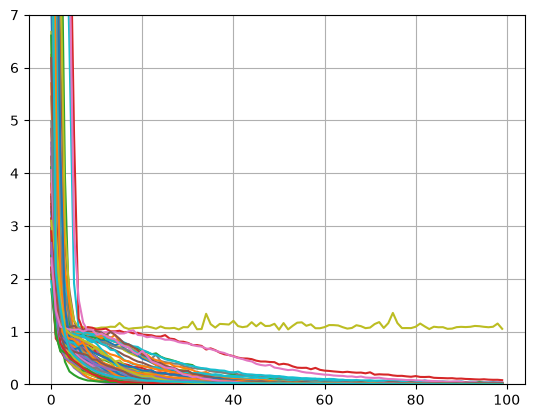

In [19]:
plt.plot( np.array(loss_log_hist).T )
#plt.xlim(-1,50)
plt.ylim(0,7)
plt.grid()
plt.show()

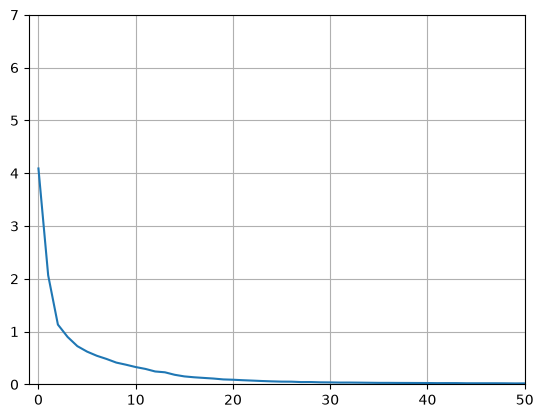

In [20]:
plt.plot( np.median(np.array(loss_log_hist),axis=0) )
plt.xlim(-1,50)
plt.ylim(0,7)
plt.grid()
plt.show()

In [21]:
# 配列を保存
np.save("loss_log_hist_biasfree.npy", np.array(loss_log_hist))

# 配列を読み込み
#loss_log_hist = np.load("loss_log_hist_biasfree.npy")

---

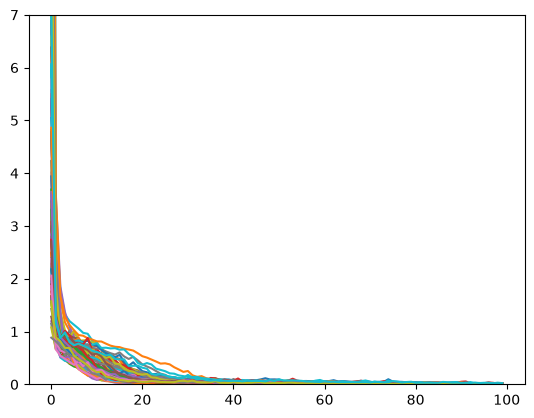

In [22]:
import copy
from IPython.display import clear_output
import time

loss_log_hist = []
for iter in range(100):

    print(f"Iteration: {iter}")

    model = FFN( ffn_base((1,4,1),bias=True) ).to(device)
    print(model)

    #loss_fn = nn.MSELoss(reduction='sum')
    #loss_fn = nn.L1Loss(reduction='sum')
    #optimizer = torch.optim.SGD(model.parameters(), lr=1e-3, momentum=0.9) # weight_decay=5e-4
    #optimizer = torch.optim.SGD(model.parameters(), lr=1e-2) # weight_decay=5e-4
    #optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

    #loss_log = train_loop(train_dataloader,model,nn.MSELoss(reduction='sum'),torch.optim.Adam(model.parameters(), lr=1e-1),epochs=100)
    loss_log = train_loop(train_dataloader,model,nn.MSELoss(reduction='mean'),torch.optim.Adam(model.parameters(), lr=5e-2),epochs=100)

    loss_log_hist.append(loss_log)

    #if iter == 0 or loss_log[-1] < min_loss:
    #    min_loss = loss_log[-1]
    #    best_loss_log = copy.copy(loss_log)
    #    best_model = copy.deepcopy(model)
    #
    #    torch.save(best_loss_log, 'best_loss_log_baseline.pth')
    #    torch.save(best_model.state_dict(), 'best_model_baseline.pth')

    torch.save(model.state_dict(), f'./model/model_baseline{iter:02d}.pth')

    clear_output(wait=True) 
    time.sleep(0.5)

# 配列を保存
np.save("loss_log_hist_baseline.npy", np.array(loss_log_hist))

loss_log_hist = np.load('loss_log_hist_baseline.npy')
plt.plot( np.array(loss_log_hist).T )
#plt.xlim(-1,50)
plt.ylim(0,7)

plt.show()

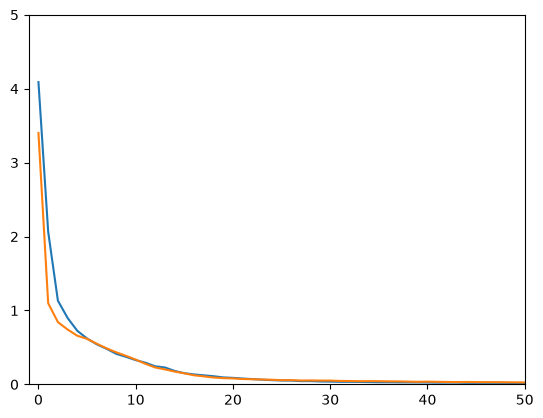

In [4]:
# 配列を読み込み
loss_log_hist1 = np.load("loss_log_hist_biasfree.npy")
loss_log_hist2 = np.load("loss_log_hist_baseline.npy")

plt.plot( np.median(np.array(loss_log_hist1),axis=0) )
plt.plot( np.median(np.array(loss_log_hist2),axis=0) )

plt.xlim(-1,50)
plt.ylim(0,5)

plt.show()

---

FFN(
  (layer_stack): Sequential(
    (0): Linear(in_features=1, out_features=4, bias=False)
    (1): Sigmoid()
    (2): Linear(in_features=4, out_features=1, bias=False)
  )
)


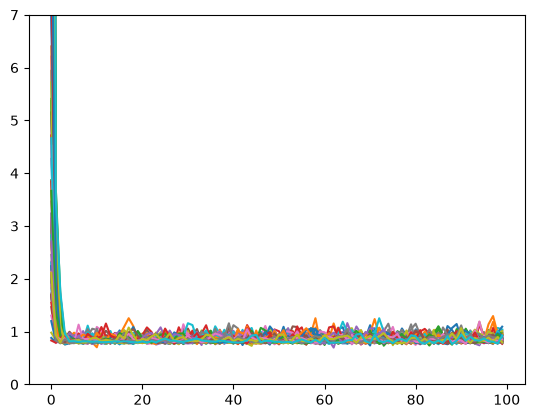

In [24]:
import copy
from IPython.display import clear_output
import time

loss_log_hist = []
for iter in range(100):

    print(f"Iteration: {iter}")

    model = FFN( ffn_base((1,4,1),bias=False) ).to(device)
    print(model)

    #loss_fn = nn.MSELoss(reduction='sum')
    #loss_fn = nn.L1Loss(reduction='sum')
    #optimizer = torch.optim.SGD(model.parameters(), lr=1e-3, momentum=0.9) # weight_decay=5e-4
    #optimizer = torch.optim.SGD(model.parameters(), lr=1e-2) # weight_decay=5e-4
    #optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

    #loss_log = train_loop(train_dataloader,model,nn.MSELoss(reduction='sum'),torch.optim.Adam(model.parameters(), lr=1e-1),epochs=100)
    loss_log = train_loop(train_dataloader,model,nn.MSELoss(reduction='mean'),torch.optim.Adam(model.parameters(), lr=5e-2),epochs=100)

    loss_log_hist.append(loss_log)

    #if iter == 0 or loss_log[-1] < min_loss:
    #    min_loss = loss_log[-1]
    #    best_loss_log = copy.copy(loss_log)
    #    best_model = copy.deepcopy(model)
    #
    #    torch.save(best_loss_log, 'best_loss_log_baseline_biasfree.pth')
    #    torch.save(best_model.state_dict(), 'best_model_baseline_biasfree.pth')
    
    torch.save(model.state_dict(), f'./model/model_baseline_biasfree{iter:02d}.pth')

    clear_output(wait=True) 
    time.sleep(0.5)

print(model)

# 配列を保存
np.save("loss_log_hist_baseline_biasfree.npy", np.array(loss_log_hist))

plt.plot( np.array(loss_log_hist).T )
#plt.xlim(-1,50)
plt.ylim(0,7)

plt.show()

---

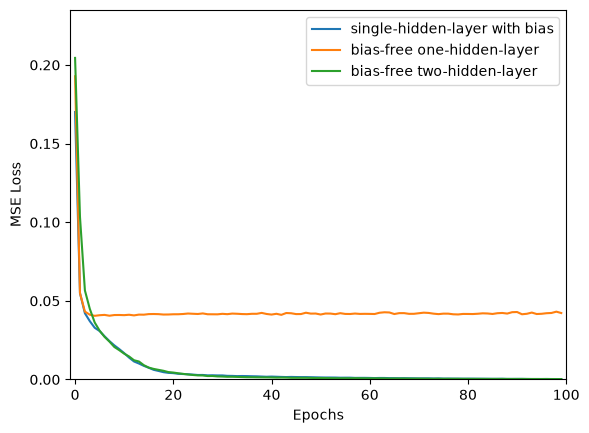

In [5]:
# Convert the sum of 20 mini-batch MSE values to the epoch-mean MSE.
loss_log_hist1 = np.load("loss_log_hist_baseline.npy")/20
loss_log_hist2 = np.load("loss_log_hist_baseline_biasfree.npy")/20
loss_log_hist3 = np.load("loss_log_hist_biasfree.npy")/20

plt.plot(np.median(loss_log_hist1,axis=0),label='single-hidden-layer with bias')
plt.plot(np.median(loss_log_hist2,axis=0),label='bias-free one-hidden-layer')
plt.plot(np.median(loss_log_hist3,axis=0),label='bias-free two-hidden-layer')

plt.xlabel('Epochs')
plt.ylabel('MSE Loss')

plt.xlim(-1,100)
plt.ylim(0,4.7/20)
plt.legend()

plt.show()

In [6]:
Nk=99
print('Final MSE:')

Q1 = np.percentile(loss_log_hist1[:,Nk], 25); Q3 = np.percentile(loss_log_hist1[:,Nk], 75)
print( f'one hidden layer \t\t\t mean±std: {loss_log_hist1[:,Nk].mean():.5f}±{loss_log_hist1[:,Nk].std():.5f}, median[Q1,Q3]: {np.median(loss_log_hist1[:,Nk]):.5f}[{Q1:.5f},{Q3:.5f}], min:{loss_log_hist1[:,Nk].min():.5f}, max:{loss_log_hist1[:,Nk].max():.5f}' )

Q1 = np.percentile(loss_log_hist2[:,Nk], 25); Q3 = np.percentile(loss_log_hist2[:,Nk], 75)
print( f'one hidden layer excluding biases \t mean±std: {loss_log_hist2[:,Nk].mean():.5f}±{loss_log_hist2[:,Nk].std():.5f}, median[Q1,Q3]: {np.median(loss_log_hist2[:,Nk]):.5f}[{Q1:.5f},{Q3:.5f}], min={loss_log_hist2[:,Nk].min():.5f}, max:{loss_log_hist2[:,Nk].max():.5f}' )

Q1 = np.percentile(loss_log_hist3[:,Nk], 25); Q3 = np.percentile(loss_log_hist3[:,Nk], 75)
print( f'two hidden layer excluding biases \t mean±std: {loss_log_hist3[:,Nk].mean():.5f}±{loss_log_hist3[:,Nk].std():.5f}, median[Q1,Q3]: {np.median(loss_log_hist3[:,Nk]):.5f}[{Q1:.5f},{Q3:.5f}], min={loss_log_hist3[:,Nk].min():.5f}, max:{loss_log_hist3[:,Nk].max():.5f}' )



Final MSE:
one hidden layer 			 mean±std: 0.00033±0.00025, median[Q1,Q3]: 0.00028[0.00014,0.00043], min:0.00002, max:0.00116
one hidden layer excluding biases 	 mean±std: 0.04307±0.00319, median[Q1,Q3]: 0.04226[0.04068,0.04482], min=0.03841, max:0.05465
two hidden layer excluding biases 	 mean±std: 0.00094±0.00522, median[Q1,Q3]: 0.00029[0.00017,0.00048], min=0.00005, max:0.05261


In [27]:
loss_log_hist3[:,99]

array([3.19019439e-03, 3.95031101e-03, 1.86536731e-03, 3.75600908e-03,
       3.46854458e-03, 4.97002131e-03, 2.94346804e-03, 6.65920169e-03,
       1.75355067e-02, 6.89927931e-03, 4.75584356e-03, 6.98702679e-03,
       5.14255905e-03, 4.69578757e-03, 8.37470153e-03, 4.16256967e-03,
       9.45967807e-04, 7.95736307e-03, 2.21727644e-02, 3.33086965e-03,
       1.22432236e-02, 1.15550033e-03, 1.21592365e-02, 9.04432125e-03,
       3.27944050e-03, 3.24457333e-03, 1.53329881e-03, 1.50173820e-02,
       1.19181215e-02, 4.84804601e-03, 1.31107969e-02, 6.26798258e-03,
       8.15688700e-03, 9.65225864e-03, 2.80658019e-03, 9.05196941e-03,
       2.38259275e-03, 7.61521572e-03, 1.05223484e+00, 1.74491878e-02,
       3.81082558e-03, 2.87447423e-02, 1.31683185e-02, 1.48662197e-02,
       7.02818235e-03, 1.02245919e-02, 5.40365509e-03, 2.21280965e-03,
       9.43733710e-03, 4.12140198e-02, 6.37541967e-03, 1.62710397e-02,
       3.70901348e-03, 1.04626469e-03, 1.33423125e-03, 2.57297358e-03,
      

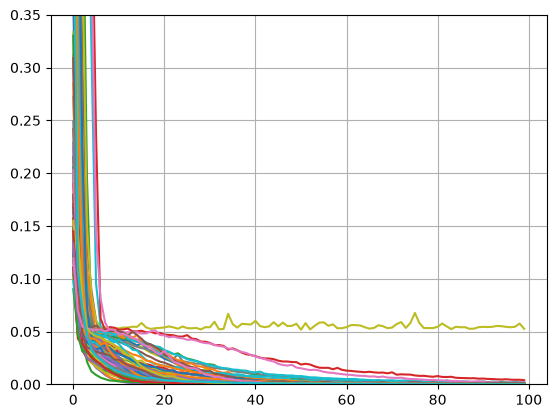

In [8]:
plt.plot(loss_log_hist3.T)
plt.ylim(0,7/20)
plt.grid()
plt.show()
plt.show()

0.00028
0.04231
0.00030


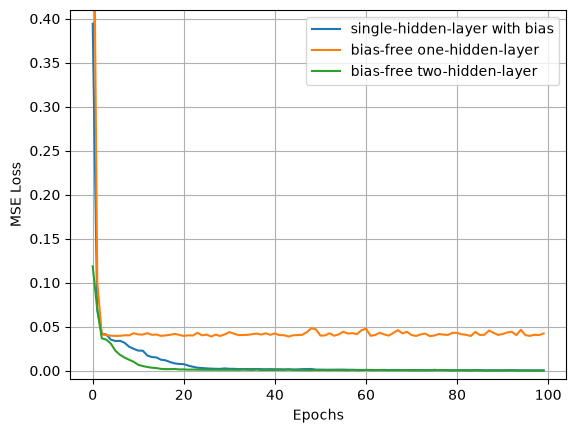

In [12]:
Nk = 99
idx1 = np.argmin( np.abs( np.median(loss_log_hist1[:,Nk])-loss_log_hist1[:,Nk] ) )
idx2 = np.argmin( np.abs( np.median(loss_log_hist2[:,Nk])-loss_log_hist2[:,Nk] ) )
idx3 = np.argmin( np.abs( np.median(loss_log_hist3[:,Nk])-loss_log_hist3[:,Nk] ) )

print( f'{loss_log_hist1[idx1,Nk]:0.5f}' )
print( f'{loss_log_hist2[idx2,Nk]:0.5f}' )
print( f'{loss_log_hist3[idx3,Nk]:0.5f}' )

plt.plot(loss_log_hist1[idx1,:],label='single-hidden-layer with bias')
plt.plot(loss_log_hist2[idx2,:],label='bias-free one-hidden-layer')
plt.plot(loss_log_hist3[idx3,:],label='bias-free two-hidden-layer')

plt.xlabel('Epochs')
plt.ylabel('MSE Loss')

plt.ylim(-0.2/20,8.2/20)
#plt.xlim(-1,100)
plt.grid()
plt.legend()

plt.savefig('ToyExample_Loss_Revised.pdf', format='pdf', bbox_inches='tight',transparent=True)


plt.show()

---

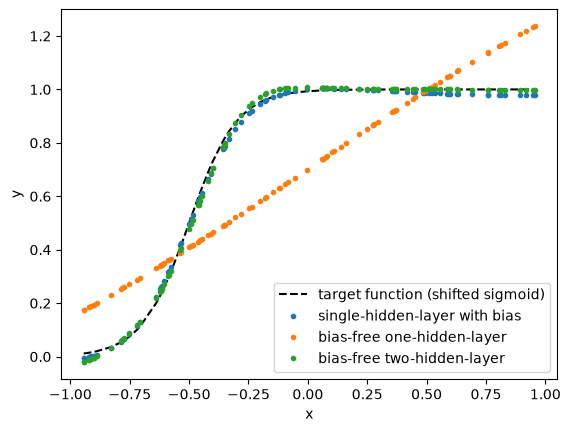

In [72]:
model1 = FFN( ffn_base((1,4,1),bias=True) ).to(device)
model2 = FFN( ffn_base((1,4,1),bias=False) ).to(device)
model3 = FFN( ffn_base((1,4,2,1),bias=False) ).to(device)

model1.load_state_dict(torch.load(f"model/model_baseline{idx1:02d}.pth"))
model2.load_state_dict(torch.load(f"model/model_baseline_biasfree{idx2:02d}.pth"))
model3.load_state_dict(torch.load(f"model/model_biasfree{idx3:02d}.pth"))

#TrainDatasetから学習データを取り出す方法
#  train_dataset[:][0] #入力
#  train_dataset[:][1] #出力（教師）
Xt = (train_dataset[:][0]).reshape(100,1).to(device) #1次元データの場合は明示的に縦ベクトル化する必要有り

y1= model1(Xt)
y2= model2(Xt)
y3= model3(Xt)

plt.plot(np.sort(x),f(np.sort(x)),'k--',label='target function (shifted sigmoid)')

plt.plot(x,y1.cpu().detach().numpy(),'.',label='single-hidden-layer with bias')
plt.plot(x,y2.cpu().detach().numpy(),'.',label='bias-free one-hidden-layer')
plt.plot(x,y3.cpu().detach().numpy(),'.',label='bias-free two-hidden-layer')

plt.xlabel('x')
plt.ylabel('y')
plt.legend(loc='lower right')
#plt.grid()

plt.savefig('ToyExample_Plot.pdf', format='pdf', bbox_inches='tight',transparent=True)

plt.show()